#PROJECT: Visual Inspection of Motorcycle Connecting Rods

This software system aimed at visual inspection of motorcycle connecting rods. The system should be able to analyse the dimensions of two different types of connecting rods (Type A rods with one hole & Type B rods have two holes).


Add Libraries:

In [ ]:
import cv2
import os
import numpy as np
from google.colab import drive
from matplotlib import pyplot as plt
from scipy.spatial import distance as dist

Mount Drive and Load Images Folder

In [ ]:
# Mount Google Drive
drive.mount('/content/drive')

# Define path to the 'images' folder inside your Drive. Update the path accordingly where your folder is.
folder_path = "/content/drive/MyDrive/images"

Mounted at /content/drive


Function to load image

In [ ]:
# Function to load image
def load_image(path, image):
    image_path = os.path.join(path, image)
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        print(f"Unable to load: {image_path}")
    return img

Image Display Function

In [ ]:
# Function to show image
def show_image(ax, image, title="", cmap='gray'):
    ax.imshow(image, cmap=cmap)
    ax.axis('off')
    ax.set_title(title)

Histogram Plotting Function

In [ ]:
#Functio to plot Histrograms
def plot_histogram(image, title="Histogram", ax=None):
    if ax is None:
        plt.figure()
        plt.hist(image.ravel(), bins=256, range=(0, 256), color='cyan')
        plt.title(title)
        plt.xlim([0, 256])
        plt.xlabel("Pixel Intensity")
        plt.ylabel("Frequency")
        plt.grid(True, linestyle='--', linewidth=0.5)
        plt.show()
    else:
        ax.hist(image.ravel(), bins=256, range=(0, 256), color='cyan')
        ax.set_title(title)
        ax.set_xlim([0, 256])
        ax.set_xlabel("Pixel Intensity")
        ax.set_ylabel("Frequency")
        ax.grid(True, linestyle='--', linewidth=0.5)

#FIRST TASK:

Provide the following information:
1. Type of rod (A or B).
2. Position and orientation (modulo )
3. Length (L), Width (W), Width at the barycenter (WB).
4. For each hole, position of the centre and diameter size.


**Image Analysis and Creating Histogram:**
Perform histogram analysis to understand the intensity distribution of the image, which helps in selecting appropriate thresholding techniques for segmentation.

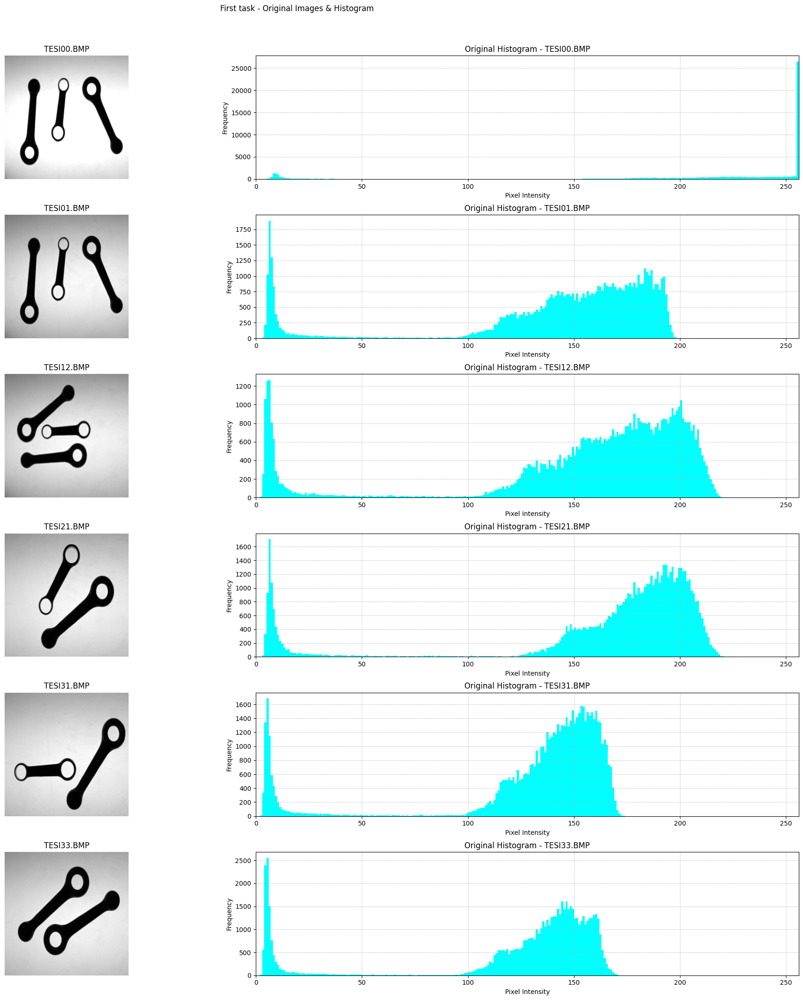

In [ ]:
# Defining Image Group in Dictionary for First Task
first_task = dict.fromkeys(["TESI00.BMP", "TESI01.BMP", "TESI12.BMP", "TESI21.BMP", "TESI31.BMP", "TESI33.BMP"], None)

# Defining function for analysis and creating histogram of Images in Group
def original_image_analysis(task, task_name):
    for key in task.keys():
        task[key] = {"original" : load_image(folder_path, key)}

    fig, axs = plt.subplots(nrows=len(task), ncols=2, figsize=(22, 22))
    fig.suptitle(task_name+' - Original Images & Histogram')

    # adds a enumerate counter to an above group
    for i, key in enumerate(task.keys()):

        # Original image display function
        show_image(axs[i, 0], task[key]["original"], title=key)

        # Calling histogram plotting Function
        plot_histogram(task[key]["original"], title=f"Original Histogram - {key}", ax=axs[i, 1])

    plt.tight_layout()
    plt.subplots_adjust(top=0.93)
    plt.show()
    return task

first_task = original_image_analysis(first_task, "First task")

**Image Denoising for Better Image Detection:**
Apply Gaussian Blur to reduce noise while preserving edges, improving the accuracy of contour detection.

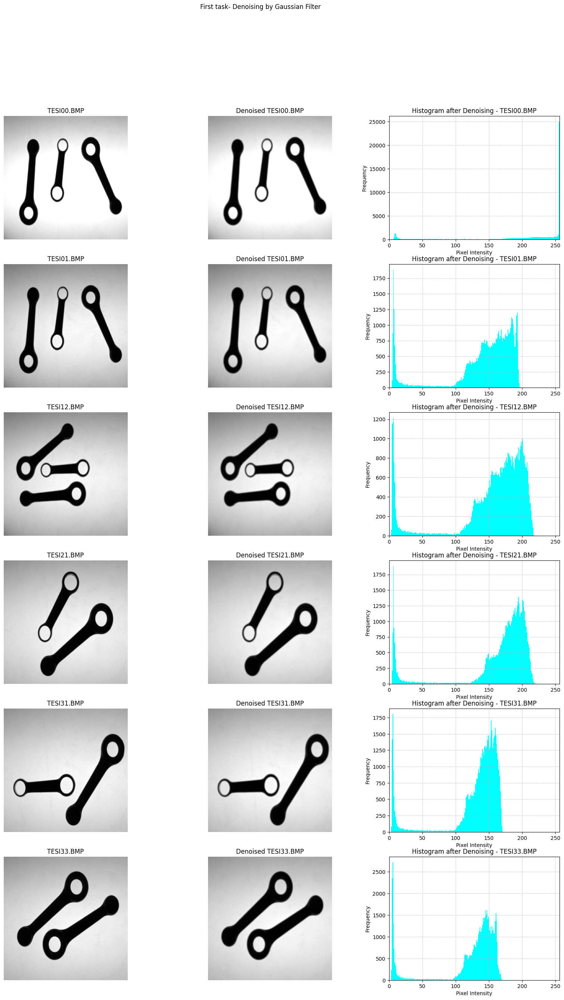

In [ ]:

def image_denoising(task, task_name):

    fig, axs = plt.subplots(nrows=len(task), ncols=3, figsize=(20, 30))
    fig.suptitle(task_name+'- Denoising by Gaussian Filter')
    for i, key in enumerate(task.keys()):

        # plot original image
        show_image(axs[i, 0], task[key]["original"], title=key)

        # plot images after Gaussian Filter
        task[key]["denoised"] = cv2.GaussianBlur(task[key]["original"], (3, 3), 0)
        show_image(axs[i, 1], task[key]["denoised"], title="Denoised " + key)

        # plot histogram of images after gaussian filter
        plot_histogram(task[key]["denoised"], title=f"Histogram after Denoising - {key}", ax=axs[i, 2])

    plt.show()
    return task

first_task = image_denoising(first_task, "First task")


**Image Segmentation (After Denoising Image):**
 Apply Otsu’s thresholding method to automatically find an optimal threshold value that separates foreground (objects like rods or distractors) from the background, resulting in a clean binary image for further processing.

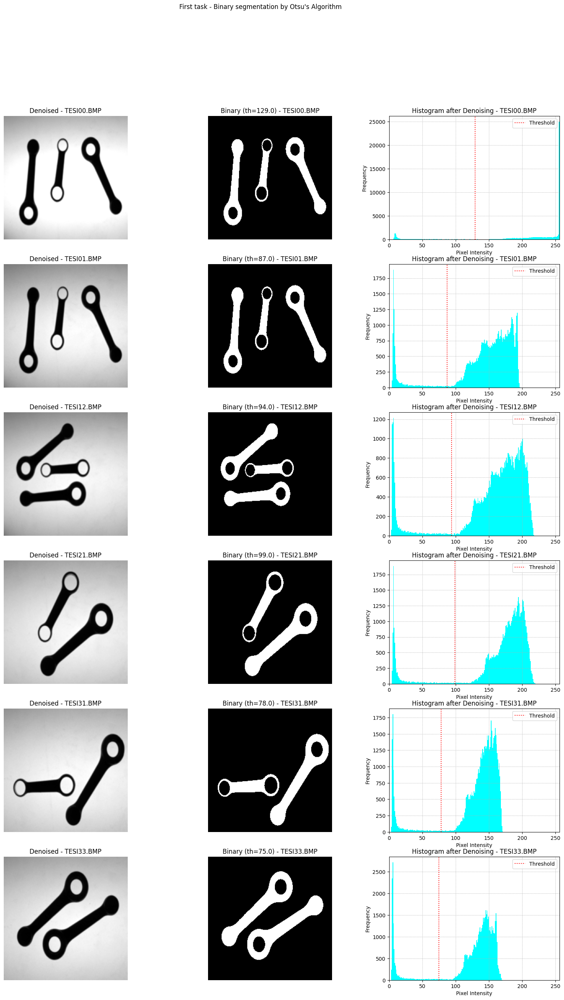

In [ ]:
def image_segmentation(task, task_name):

    fig, axs = plt.subplots(nrows=len(task), ncols=3, figsize=(20, 30))
    fig.suptitle(task_name +" - Binary segmentation by Otsu's Algorithm")

    for i, key in enumerate(task.keys()):
        # Display Denoised Image
        show_image(axs[i, 0], task[key]["denoised"], title="Denoised - " + key)

        # plot threshold line on images after segmentation
        threshold, binary_img = cv2.threshold(task[key]["denoised"], 0, 255, cv2.THRESH_BINARY_INV |cv2.THRESH_OTSU)
        task[key]["binary"] = binary_img
        axs[i, 2].axvline(x=threshold, color='r',linestyle=':', label='Threshold')
        axs[i, 2].legend(loc='best')

         # Display Binary Image of Denoised Image
        show_image(axs[i, 1], task[key]["binary"], title="Binary (th="+str(threshold)+") - " + key)

        # plot histogram of images after denoising
        plot_histogram(task[key]["denoised"], title=f"Histogram after Denoising - {key}", ax=axs[i, 2])

    plt.show()
    return task

first_task = image_segmentation(first_task, "First task")


**Compute the Number of Connected Components:**
Use the connectedComponents function to identify and count all distinct connected regions (components) in the binary image.

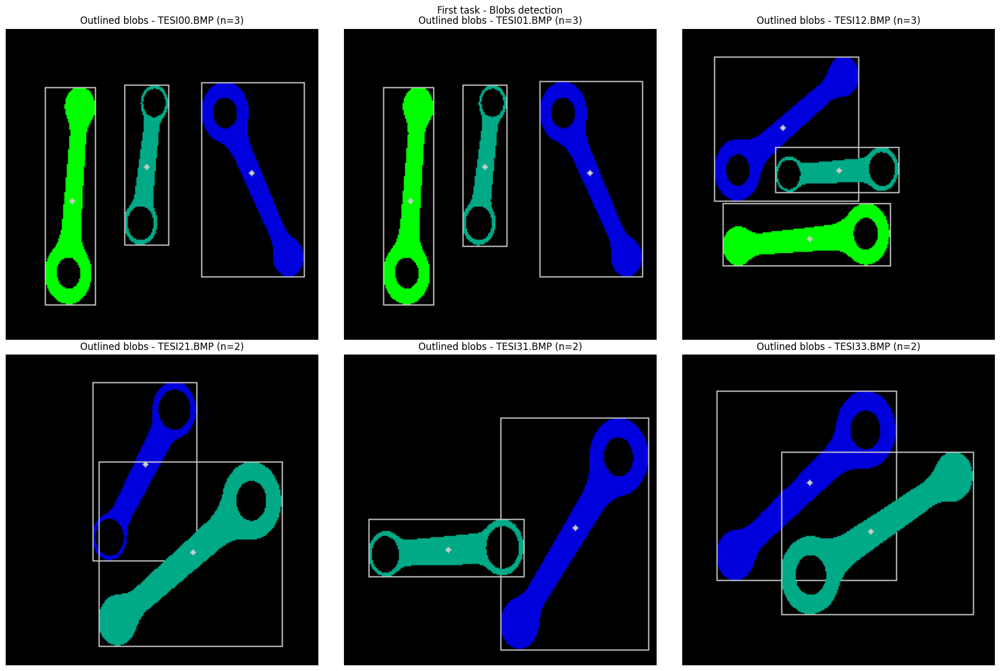

In [ ]:
# Compute the number of connected components in the image
def connected_componentets_analysis(img, connectivity=8):

    n_labels, label_ids, stats, centroid = cv2.connectedComponentsWithStats(img, connectivity=connectivity)
    return n_labels, label_ids, stats, centroid

# Show the blobs in the image
def show_blobs(n_labels, label_ids, stats, centroid, bbox_color=5):

    output = np.zeros(label_ids.shape, dtype="uint8")

    for i in range(1, n_labels):
        # stores all the IDs of the components on the each pixel that has the same dimension as the threshold
            output[label_ids == i] = i

            # Now extract the coordinate points
            x1 = stats[i, cv2.CC_STAT_LEFT]
            y1 = stats[i, cv2.CC_STAT_TOP]
            w = stats[i, cv2.CC_STAT_WIDTH]
            h = stats[i, cv2.CC_STAT_HEIGHT]

            # draw bounding box and centroid
            cv2.rectangle(output, (x1, y1), (x1+w, y1+h), bbox_color, 1)
            cv2.circle(output, (int(centroid[i][0]), int(centroid[i][1])), 2, bbox_color, -1)
    return output

# Apply Blob analysis on the given images
def image_blobs_analysis(task, task_name):
    n_images = len(task)
    ncols = 3
    nrows = int(np.ceil(n_images / ncols))

    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(18, 12))
    fig.suptitle(task_name + " - Blobs detection")

    # flatten the axes for easier indexing
    axs = axs.flatten()

    for k, key in enumerate(task.keys()):
        # Connected components
        n_labels, label_ids, stats, centroid = connected_componentets_analysis(task[key]["binary"])

        # Save Results in dictionary
        task[key]["blobs"] = {
            "n_labels": n_labels,
            "label_ids": label_ids,
            "stats": stats,
            "centroid": centroid
        }

        # Identify blobs and display them on image
        blob_output = show_blobs(n_labels, label_ids, stats, centroid)
        # Displaying images with identified blobs
        show_image(axs[k], blob_output, title=f"Outlined blobs - {key} (n={n_labels - 1})", cmap='nipy_spectral')
        #axs[k].imshow(output, cmap='nipy_spectral')
        #axs[k].axis('off')
        #axs[k].set_title(f"Outlined blobs - {key} (n={n_labels - 1})")

    # Hide any unused axes
    for k in range(len(task), len(axs)):
        axs[k].axis('off')

    plt.tight_layout()
    plt.show()

    return task

first_task = image_blobs_analysis(first_task, "First task")

**Getting Blob:**  
Get the blob with the given label of the connected components.

In [ ]:
def get_blob(ids, label):
    blob = np.zeros(ids.shape, dtype=np.uint8)
    blob[ids == label] = 1
    return blob

**Compute Haralick's Circularity Measure:**
This step calculates a shape descriptor for each detected component to evaluate how close its shape is to a perfect circle.

In [ ]:
def haralick_circularity(contour, centroid):
    # Flatten contour points: each coord is [[x, y]], so use coord[0] to get [x, y]
    distances = [dist.euclidean(coord[0], centroid) for coord in contour]

    std = np.std(distances)
    return np.mean(distances) / std if std > 0 else float('INF')

**Compute Coordinates of the Barycenter(tuple) of a Blob(dict):** For each detected object (blob), calculate the barycenter (center of mass) using image moments.

In [ ]:
def compute_barycentre(moments):
    cX = int(moments["m10"] / moments["m00"])
    cY = int(moments["m01"] / moments["m00"])
    return cX, cY

**Compute the Position Of The Centre And Diameter Size For Each Hole in Blob:**
For each blob (detected connecting rod), find holes inside it by checking for inner contours. Then compute centre of each hole and diameter

In [ ]:
def get_holes_stats(contours, haralick_threshold=6):
    holes = []
    for i in range(1, len(contours)):
        # compute the barycentre of the contour
        M = cv2.moments(contours[i])
        cX, cY = compute_barycentre(M)

        # compute the area of the contour
        area = cv2.contourArea(contours[i])

        # compute haralick's circularity
        circularity_score = haralick_circularity(contours[i], (cX, cY))

        # check if the contour is circular enough
        if circularity_score > haralick_threshold:
            diameter = np.sqrt(4*area/np.pi)
            holes.append({"cX": cX, "cY": cY, "diameter": diameter})
    return holes


**Compute the Orientation of the Major Axis of the Blob:**
Use central image moments to calculate the angle (θ) of the blob’s major axis, indicating its directional orientation.

In [ ]:
# Function to Compute the orientation of the major axis of the blob

def compute_major_axis_orientation(moment): # it take Moments(dict) of the blob

    # compute the orientation of the blob
    theta = -0.5 * np.arctan(
        (2 * moment['mu11']) /
        (moment['mu02'] - moment['mu20'] + 1e-5)
    )
    # determine the orientation of the major axis
    # analysis of the sign of second derivative
    second_derivative = (moment['mu02'] - moment['mu20']) * 2 * np.cos(2*theta) - 4 * moment['mu11'] * np.sin(2*theta)

    # if the second derivative is positive, we have to considere the other zero of the solution
    if second_derivative > 0:
        theta += np.pi/2

    if theta < 0:
        theta += np.pi

    # It gives theta(float) Orientation of the major axis of the blob in radiants
    return theta

**Compute the Width of the Blob Along Its Minor Axis:**
Use the equation of the minor axis through the barycenter to find two closest contour points and calculated the width as the Euclidean distance between them.

In [ ]:
def get_width_barycenter(barycentre, orientation, contour):

    #Make use of the equation of minor axis passing through the centroid of the blob

    # orientation of the minor axis
    orientation_min = orientation - np.pi/2

    # exploit the equation of a line y = m*x + q
    # where m =  tan(angle) & q = cY - (m * cX )
    m = np.tan(orientation_min)
    q = barycentre[1] - m*barycentre[0]

    # find the two point of intersection between the line and the contour
    distances = []
    for i in range(len(contour)):
        x = contour[i][0][0]
        y = contour[i][0][1]

        # compute the distance between the contour point and the point on the line
        distances.append(np.abs(y - m*x - q))

    # order the distances and get the two closest points
    idxs = np.argsort(distances)
    intersections = [contour[idxs[0]][0], contour[idxs[1]][0]]

    width = dist.euclidean(intersections[0], intersections[1])
    return width, intersections


**Image Inspection:**
The `image_inspection` function analyzes and visualizes blobs in an image, specifically identifying rod types (Type A or B) based on hole counts. It computes features such as the blob's barycenter, orientation, and width at the barycenter, then overlays this information on the image, displaying contours, bounding boxes, and axes for clear visualization.

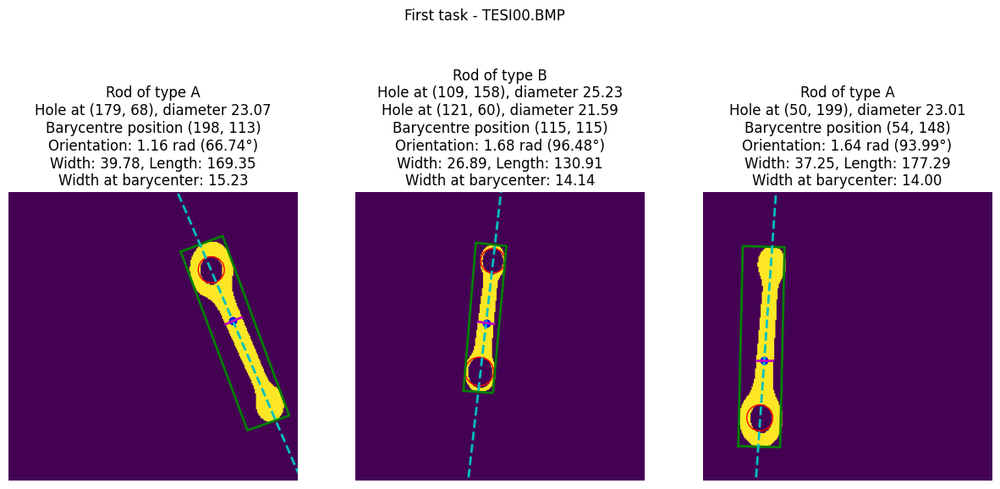

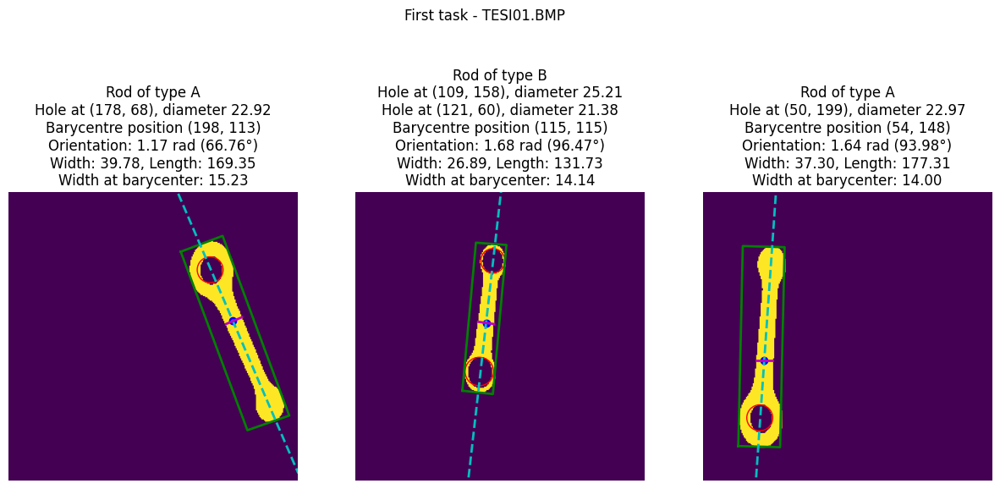

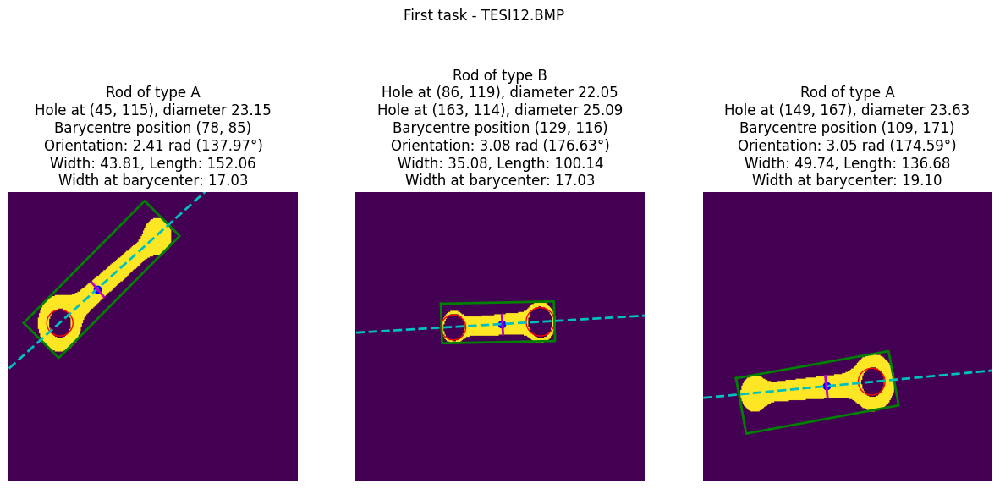

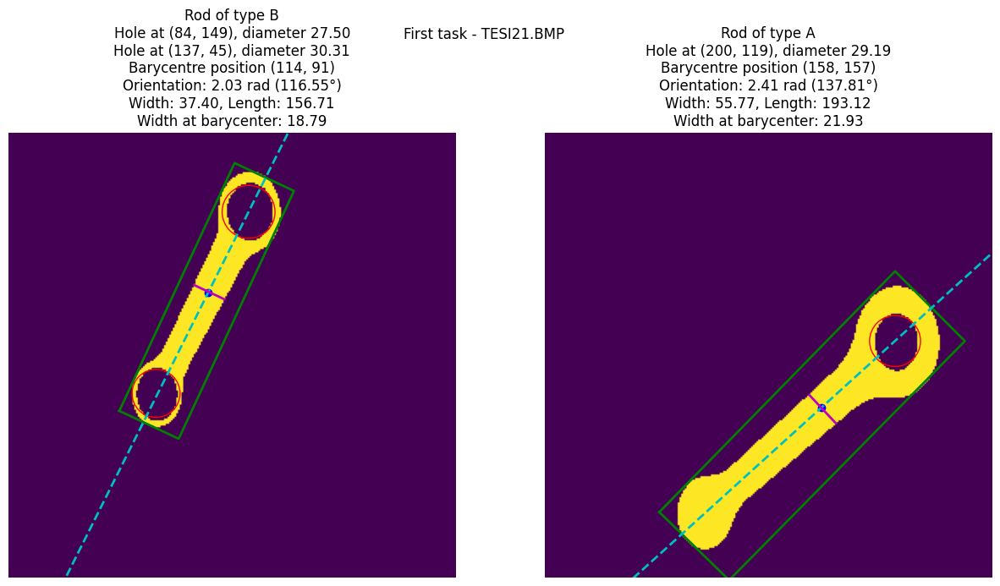

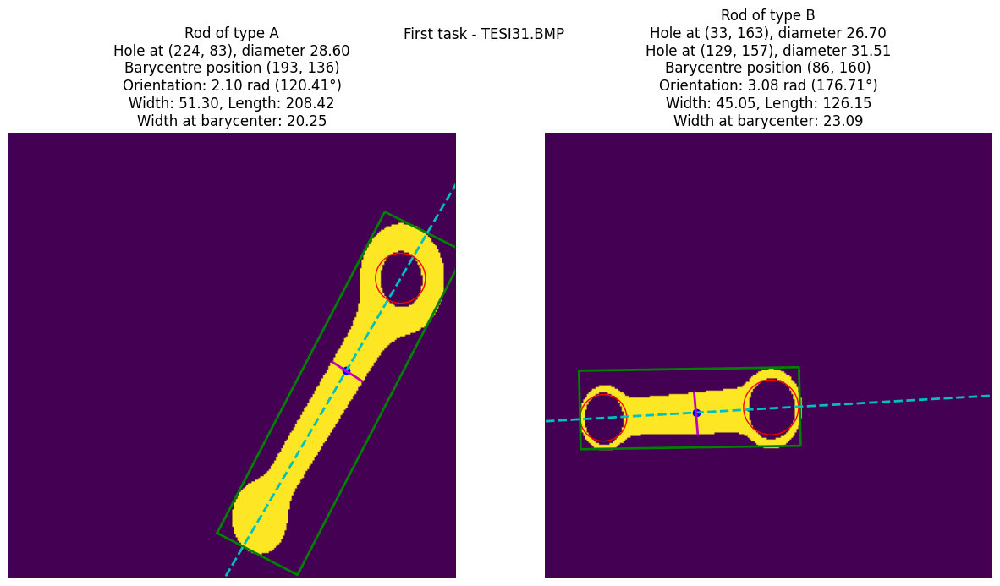

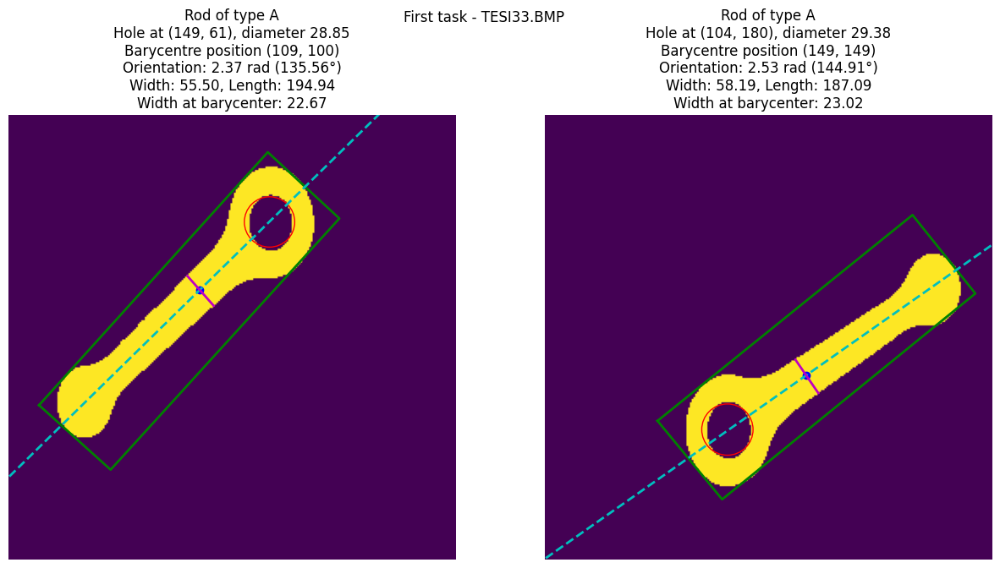

In [ ]:
def image_inspection(task, task_name):
    for key in task.keys():
        n_labels = task[key]["blobs"]["n_labels"]
        labels_ids = task[key]["blobs"]["label_ids"]
        stats = task[key]["blobs"]["stats"]

        fig, axs = plt.subplots(nrows=1, ncols=n_labels-1, figsize=(15, 8))
        fig.suptitle(task_name+" - "+key)
        for i in range(1, n_labels):
            blob = get_blob(labels_ids, i)

            # find contours of the highlighted blob
            contours, hierarchy = cv2.findContours(blob, cv2.RETR_TREE, cv2.CHAIN_APPROX_NONE)

            # compute the holes to classify the type of the rod
            holes = get_holes_stats(contours)

            title = ""

            if len(holes) == 1:
                # rod is of type A
                title+="Rod of type A\n"
            elif len(holes) == 2:
                # rod is of type B
                title+="Rod of type B\n"
            else:
                # rod is unknown type
                title+="Rod of unknown type\n"

            for hole in holes:
                title+="Hole at ({:.0f}, {:.0f}), diameter {:.2f}\n".format(hole["cX"], hole["cY"], hole["diameter"])

                # plot the hole
                axs[i-1].add_patch(plt.Circle((hole["cX"], hole["cY"]), hole["diameter"]/2, color='r', fill=False))

            # compute the minimum enclosing rectangle
            rect = cv2.minAreaRect(contours[0])
            centroid, dimesions, rotation = rect

            moment = cv2.moments(contours[0])

            # compute the orientation of the major axis
            theta = compute_major_axis_orientation(moment)
            theta_deg = np.rad2deg(theta)

            # compute the barycenter of the blob
            cX, cY = compute_barycentre(moment)

            # compute the width at the barycenter
            width_barycenter, intersections = get_width_barycenter((cX, cY), theta, contours[0])

            # get the 4 corners of the rectangle
            box = cv2.boxPoints(rect)
            #box = np.int0(box)
            box = box.astype(np.intp)
            box = np.vstack((box, box[0]))

            # plot the barycentre
            axs[i-1].plot(cX, cY, 'bo')

            # plot  rectangle
            axs[i-1].plot(box[:,0], box[:,1], color='g', linewidth=2)

            # plot the major axis
            m = np.tan(theta)
            n = cY - m*cX
            x = np.linspace(0, blob.shape[1], 100)
            y = m*x + n
            axs[i-1].plot(x, y, color='c', linestyle="--", linewidth=2)

            # plot the width at the barycenter
            axs[i-1].plot([intersections[0][0], intersections[1][0]], [intersections[0][1], intersections[1][1]], color='m', linewidth=2)

            length = np.max(dimesions)
            width = np.min(dimesions)

            # print stats on the title
            title+="Barycentre position ({:.0f}, {:.0f})\n".format(cX, cY)
            title+="Orientation: {:.2f} rad ({:.2f}°)\n".format(theta, theta_deg)
            title+="Width: {:.2f}, Length: {:.2f}\n".format(width, length)
            title+="Width at barycenter: {:.2f}".format(width_barycenter)

            # plot the blob
            axs[i-1].imshow(blob)
            axs[i-1].axis('off')
            axs[i-1].set_title(title)

        plt.show()

image_inspection(first_task, "First task")





#SECOND TASK:

While meeting requirement of the First Task, modify system in order to deal with following three changes oF the working images:
1. Images may contain other objects (i.e. screws and washers) labelled as “distractors”.

**Image Inspection with Distractors:**
Classify objects as either rods (Type A or B) or distractors based on features like hole count, circularity, and shape.The final output displays annotated images with rods and distractors identified and color-coded.

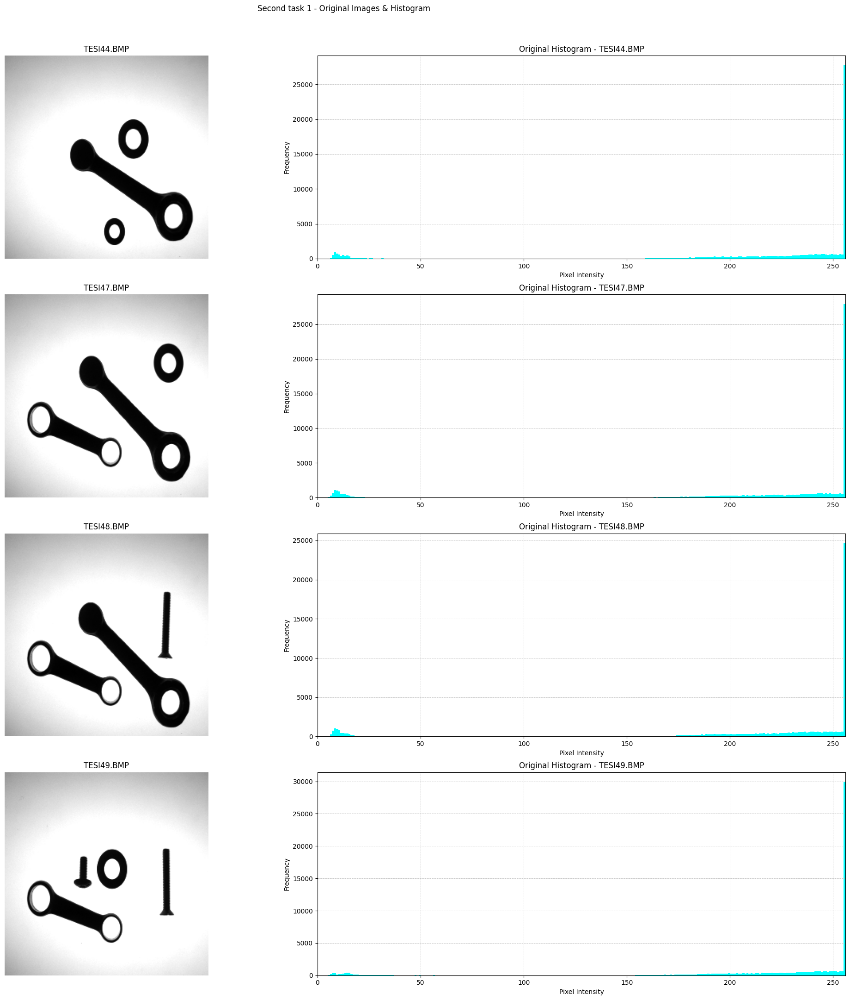

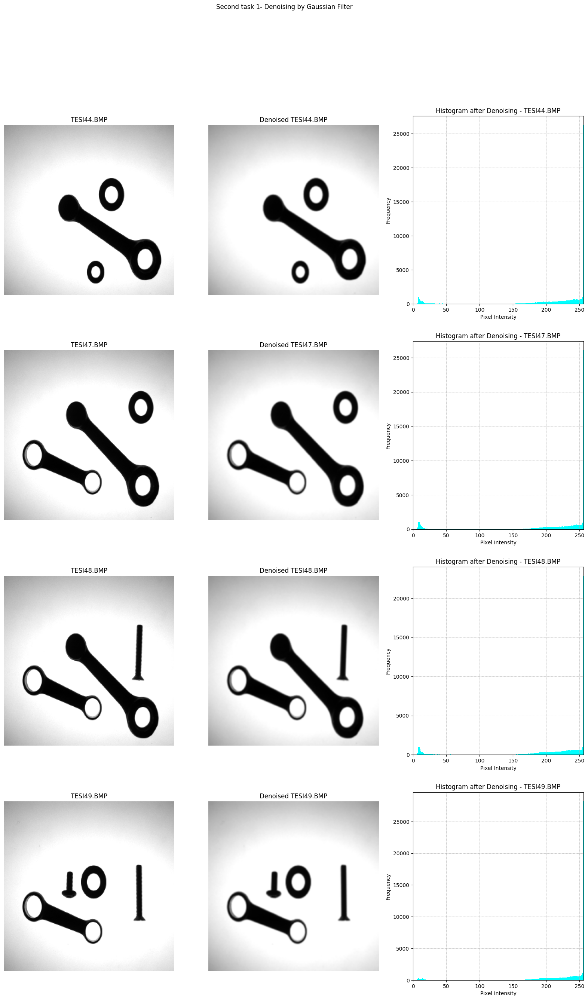

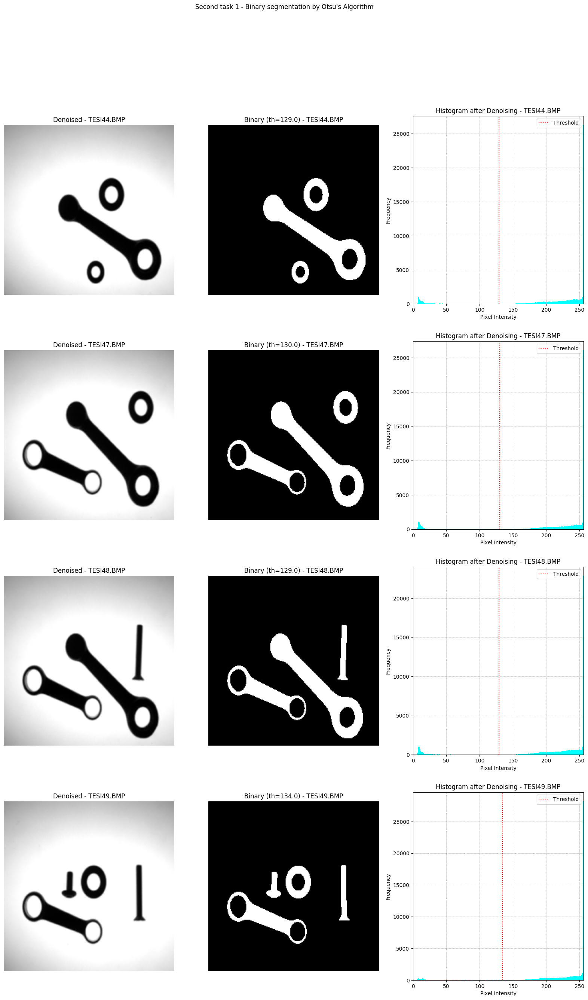

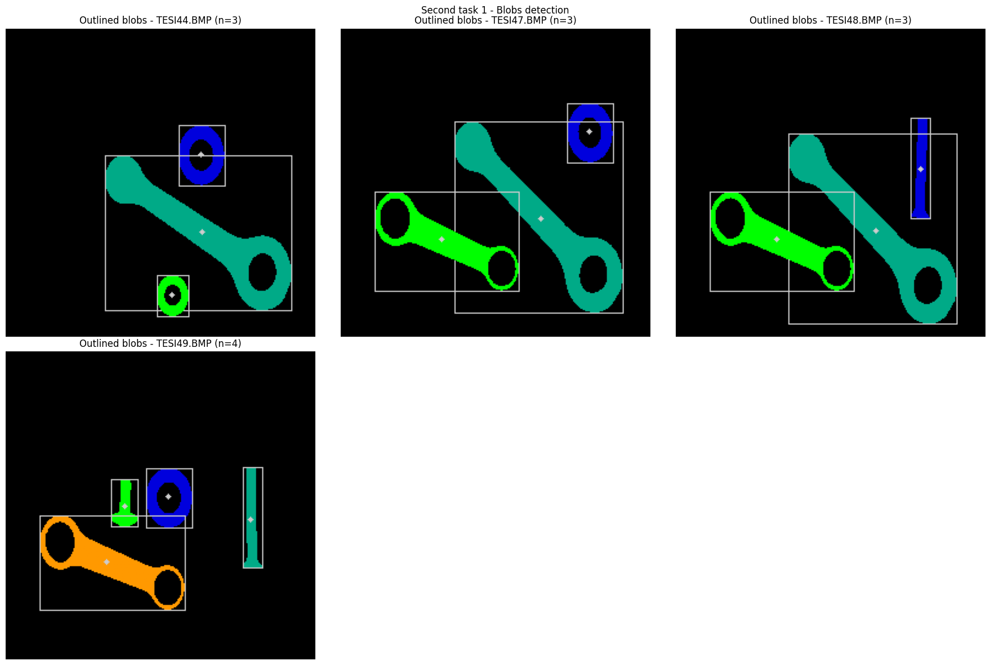

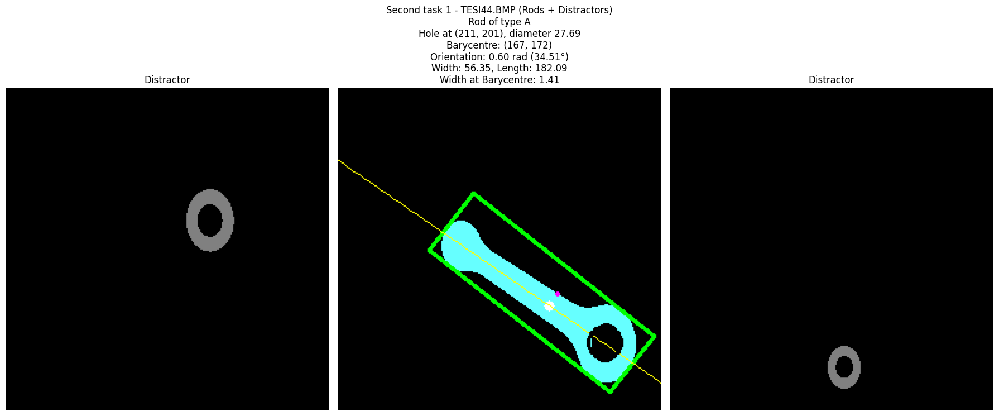

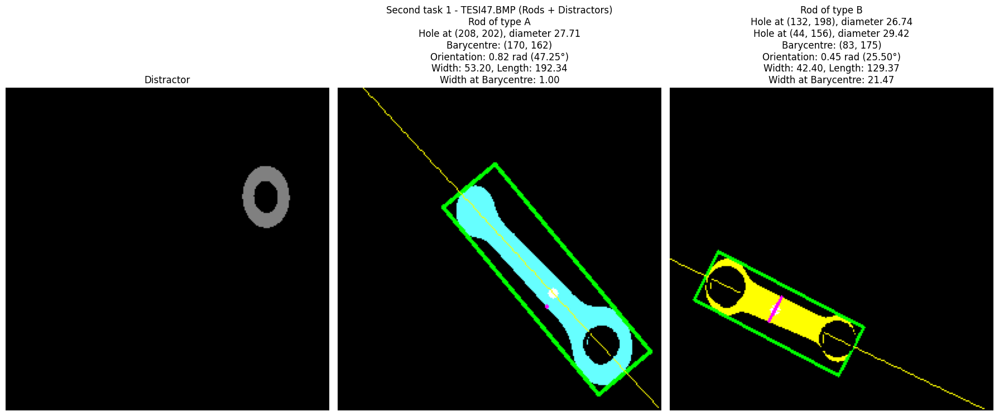

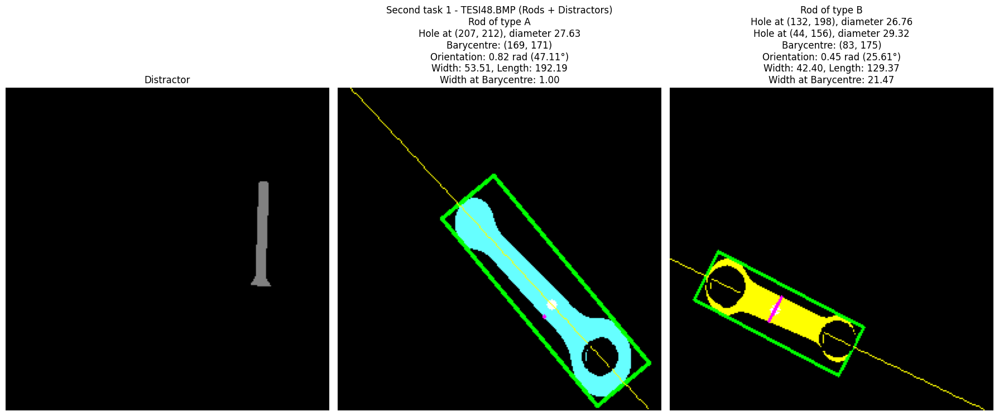

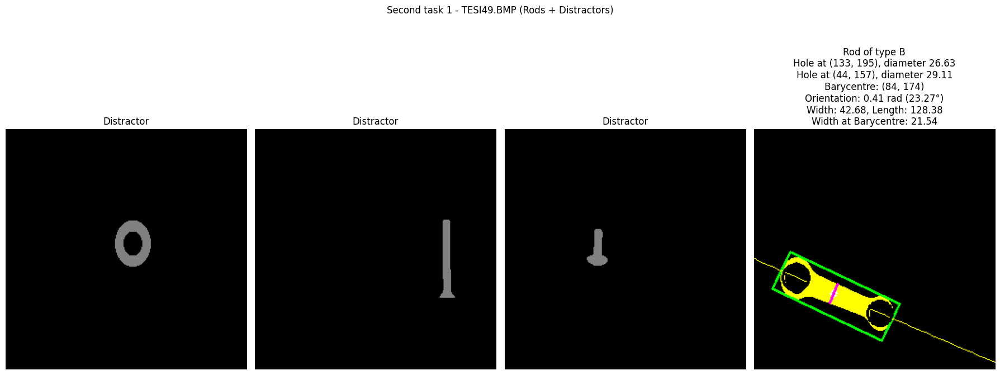

In [ ]:
#Define image group in dictionary for distractor
second_task_1 = dict.fromkeys(['TESI44.BMP', 'TESI47.BMP', 'TESI48.BMP', 'TESI49.BMP'], None)

def image_inspection_with_distractors(task, task_name):

    for key in task.keys():
        n_labels = task[key]["blobs"]["n_labels"]
        labels_ids = task[key]["blobs"]["label_ids"]
        stats = task[key]["blobs"]["stats"]

        fig, axs = plt.subplots(nrows=1, ncols=n_labels - 1, figsize=(18, 8))
        fig.suptitle(f"{task_name} - {key} (Rods + Distractors)")

        if n_labels - 1 == 1:
            axs = [axs]

        for i in range(1, n_labels):
            blob = get_blob(labels_ids, i)
            contours, _ = cv2.findContours(blob, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

            if not contours or len(contours[0]) < 5:
                axs[i - 1].imshow(blob, cmap='gray')
                axs[i - 1].set_title("Too small")
                axs[i - 1].axis('off')
                continue

            holes = get_holes_stats(contours)

            # Compute circularity
            area = cv2.contourArea(contours[0])
            perimeter = cv2.arcLength(contours[0], True)
            circularity = (4 * np.pi * area) / (perimeter ** 2) if perimeter > 0 else 0

            # Create a blank color image
            canvas = np.zeros((blob.shape[0], blob.shape[1], 3), dtype=np.uint8)

            # Classification and Fill Color
            if len(holes) == 1 and circularity < 0.85:
                rod_type = "Rod of type A"
                fill_color = (255, 255, 102)  # blue
            elif len(holes) == 2 and circularity < 0.85:
                rod_type = "Rod of type B"
                fill_color = (0, 255, 255)   # yellow
            else:
                rod_type = "Distractor"
                fill_color = (128, 128, 128)  # Gray

            # Fill the object with color
            cv2.drawContours(canvas, contours, -1, fill_color, thickness=cv2.FILLED)

            # Draw bounding box and features only for rods
            if "Rod" in rod_type:
                rect = cv2.minAreaRect(contours[0])
                box = cv2.boxPoints(rect).astype(np.intp)
                cv2.polylines(canvas, [box], isClosed=True, color=(0, 255, 0), thickness=2)

                moment = cv2.moments(contours[0])
                cX, cY = compute_barycentre(moment)
                cv2.circle(canvas, (cX, cY), 4, (255, 255, 255), -1)

                theta = compute_major_axis_orientation(moment)
                theta_deg = np.rad2deg(theta)
                width_barycenter, intersections = get_width_barycenter((cX, cY), theta, contours[0])
                length = max(rect[1])
                width = min(rect[1])

                # Draw major axis
                x = np.linspace(0, blob.shape[1], 100)
                y = np.tan(theta) * x + (cY - np.tan(theta) * cX)
                pts = np.stack((x, y), axis=1).astype(np.int32)
                for pt1, pt2 in zip(pts[:-1], pts[1:]):
                    if 0 <= pt1[1] < blob.shape[0] and 0 <= pt2[1] < blob.shape[0]:
                        cv2.line(canvas, tuple(pt1), tuple(pt2), (0, 255, 255), 1)

                # Width at barycenter
                pt1, pt2 = tuple(intersections[0]), tuple(intersections[1])
                cv2.line(canvas, pt1, pt2, (255, 0, 255), 2)

                # Annotate holes
                for hole in holes:
                    center = (int(hole["cX"]), int(hole["cY"]))
                    radius = int(hole["diameter"] / 2)
                    cv2.circle(canvas, center, radius, (0, 0, 0), 2)

                # Prepare title
                title = f"{rod_type}\n"
                for hole in holes:
                    title += f"Hole at ({hole['cX']:.0f}, {hole['cY']:.0f}), diameter {hole['diameter']:.2f}\n"
                title += f"Barycentre: ({cX:.0f}, {cY:.0f})\n"
                title += f"Orientation: {theta:.2f} rad ({theta_deg:.2f}°)\n"
                title += f"Width: {width:.2f}, Length: {length:.2f}\n"
                title += f"Width at Barycentre: {width_barycenter:.2f}"
            else:
                title = "Distractor"

            axs[i - 1].imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
            axs[i - 1].set_title(title)
            axs[i - 1].axis('off')

        plt.tight_layout()
        plt.subplots_adjust(top=0.85)
        plt.show()



second_task_1 = original_image_analysis(second_task_1, "Second task 1")
second_task_1 = image_denoising(second_task_1, "Second task 1")
second_task_1 = image_segmentation(second_task_1, "Second task 1")
second_task_1 = image_blobs_analysis(second_task_1, "Second task 1")
image_inspection_with_distractors(second_task_1, "Second task 1")

2. The inspection area may be dirty due to scattered iron powder.

**Image Denoising (Gaussian + Bilateral Filters):**
Due to the noise in the image, apply a Gaussian filter first to reduce noise by smoothing the image. Then, a Bilateral filter was used to preserve edges while further reducing noise, making the image suitable for more accurate feature extraction and analysis.

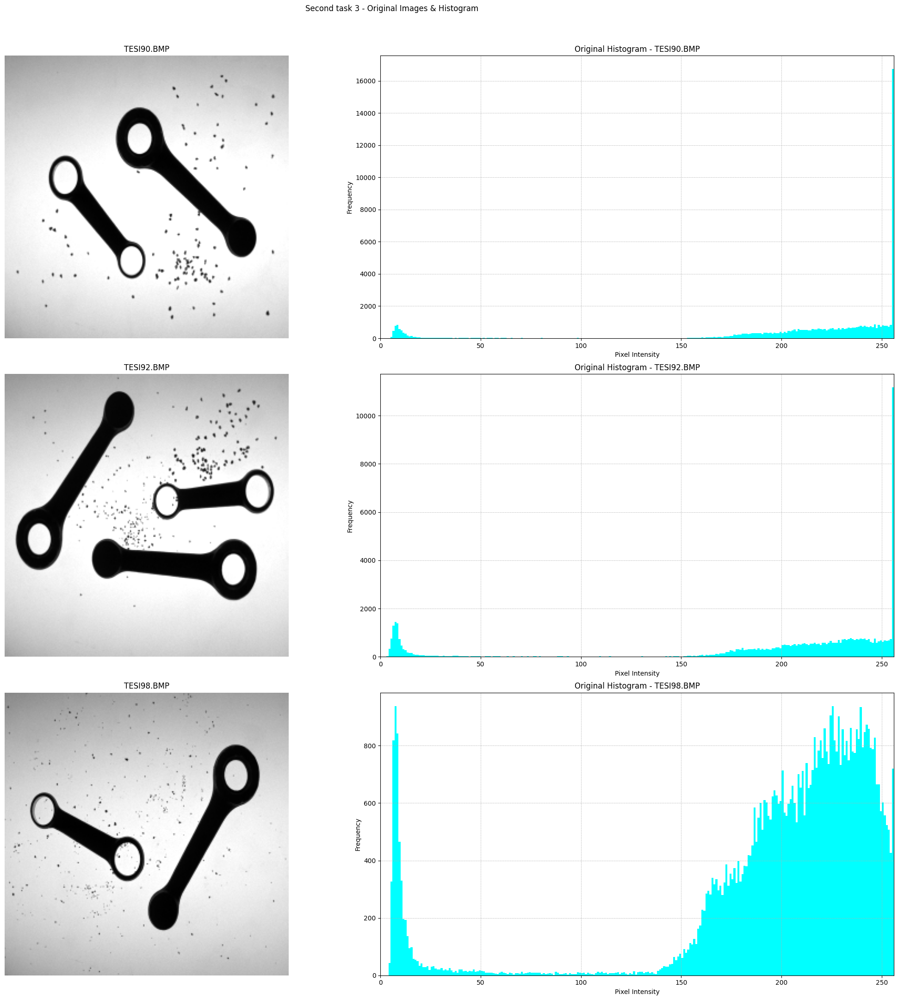

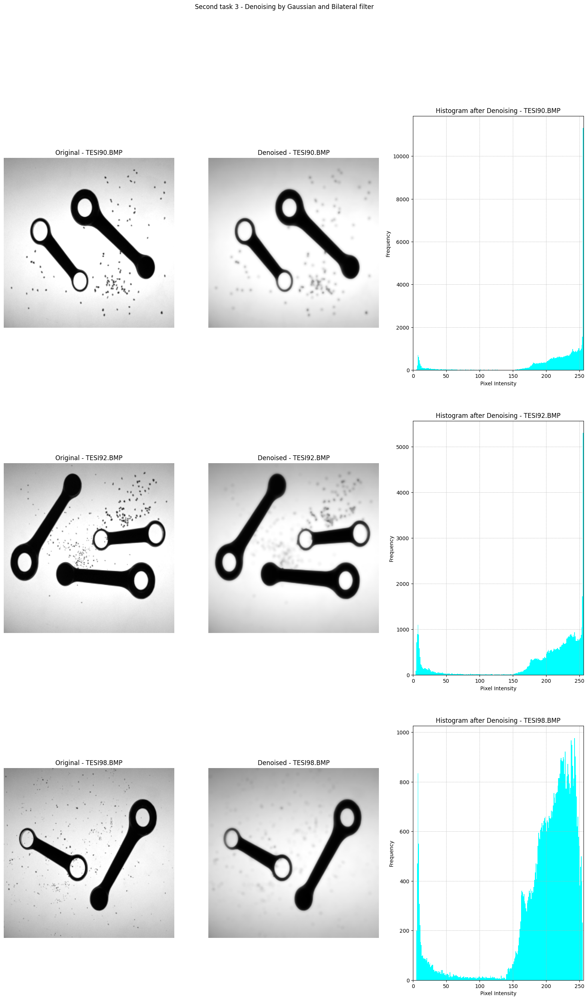

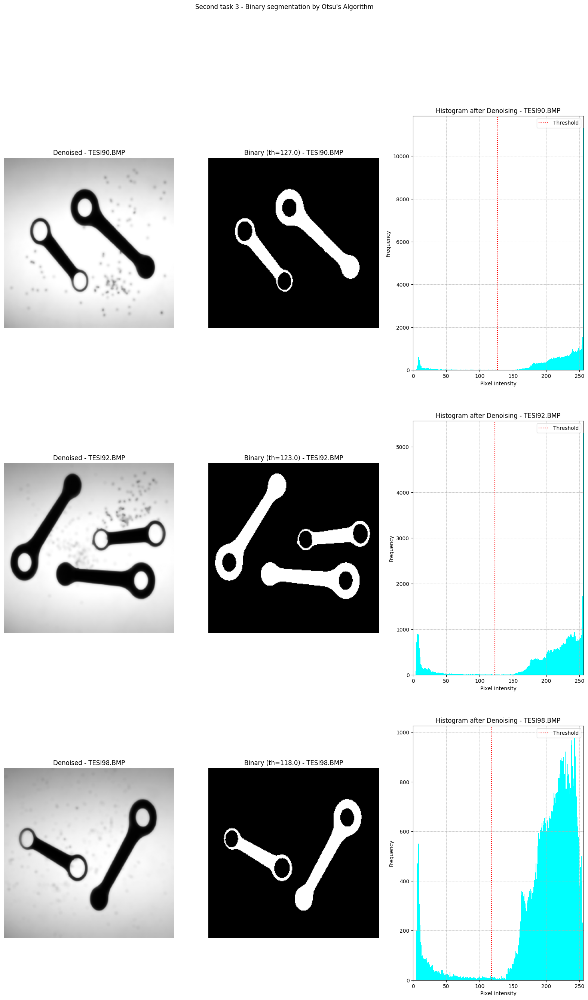

In [ ]:
#Define image group in dictionary for noisy and dirty background
second_task_3 = dict.fromkeys(['TESI90.BMP', 'TESI92.BMP', 'TESI98.BMP'],None)

def image_denoising(task, task_name):

    fig, axs = plt.subplots(nrows=len(task), ncols=3, figsize=(20, 30))
    fig.suptitle(task_name+' - Denoising by Gaussian and Bilateral filter')
    for i, key in enumerate(task.keys()):

        # plot original image
        show_image(axs[i, 0], task[key]["original"], title="Original - " + key)

        # plot images after gaussian blur and bilateral filter
        task[key]["denoised"] = cv2.GaussianBlur(task[key]["original"], (3, 3), 0)
        task[key]["denoised"] = cv2.bilateralFilter(task[key]["denoised"], d=7, sigmaColor=75, sigmaSpace=75)

        # plot original image
        show_image(axs[i, 1], task[key]["denoised"], title="Denoised - " + key)

        # plot histogram of images after gaussian filter
        plot_histogram(task[key]["denoised"], title=f"Histogram after Denoising - {key}", ax=axs[i, 2])

    plt.show()
    return task

second_task_3 = original_image_analysis(second_task_3, "Second task 3")
second_task_3 = image_denoising(second_task_3, "Second task 3")
second_task_3 = image_segmentation(second_task_3, "Second task 3")

**Connected Components Analysis with Threshold Filtering:**

The `connected_componentets_analysis()` function is redefined with a threshold parameter (set to 100) to filter out blobs with an area smaller than the specified minimum, effectively discarding small granules from iron powder noise.Then finally call the image inspection function.


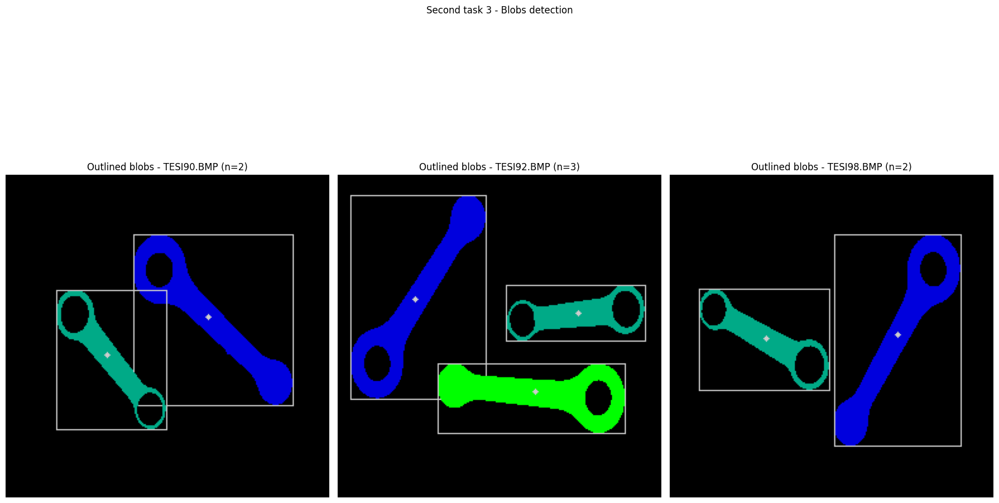

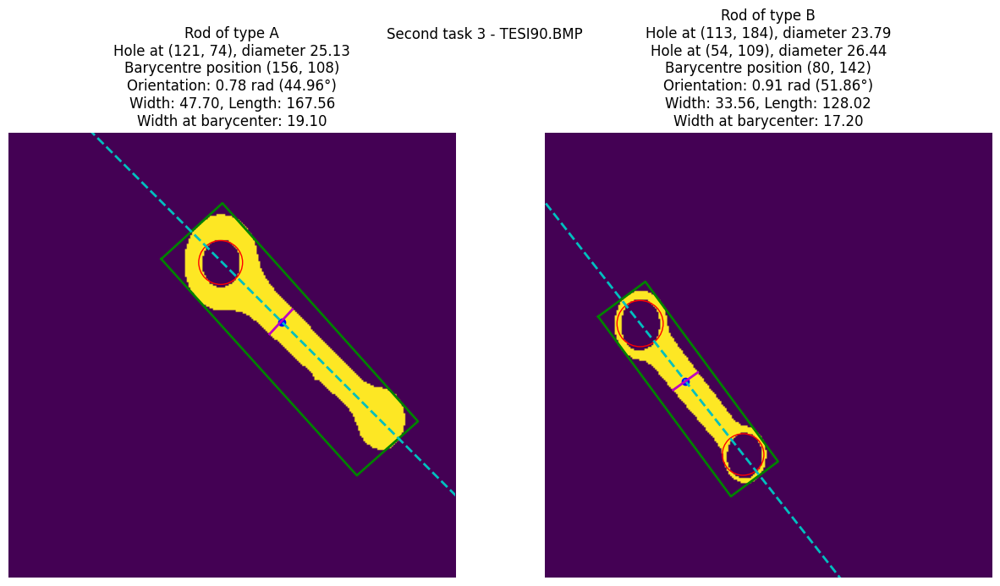

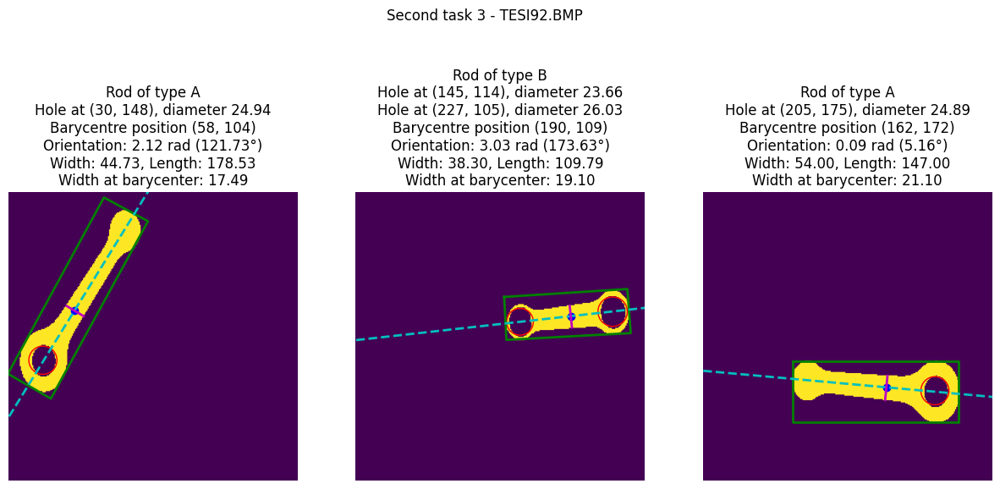

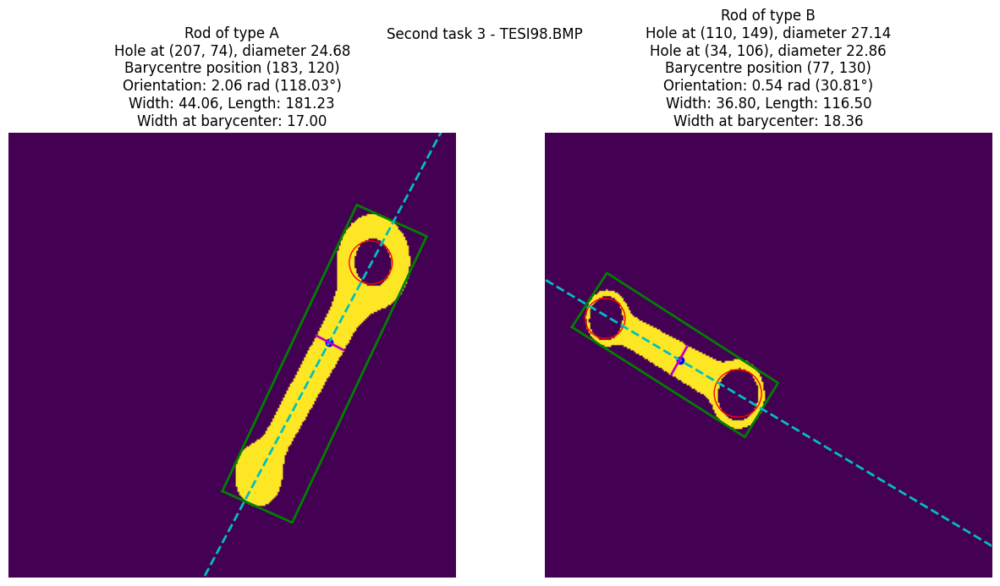

In [ ]:
def connected_componentets_analysis(img, connectivity=8, area_threshold=100):


    n_labels, label_ids, stats, centroid = cv2.connectedComponentsWithStats(img, connectivity=connectivity)

    idx_thresh = np.where(stats[:, cv2.CC_STAT_AREA] > area_threshold)[0]
    stats = stats[idx_thresh]
    centroid = centroid[idx_thresh]
    n_labels = len(stats)

    # keep only the connected components with area greater than the threshold, all the others are set to background
    inds = label_ids == idx_thresh[:, None, None]
    label_ids[~np.any(inds, axis = 0)] = 0

    # shrink the label ids to the range [0, n_labels-1]
    for value, i in enumerate(idx_thresh):
        label_ids[label_ids == i] = value

    return n_labels, label_ids, stats, centroid

second_task_3 = image_blobs_analysis(second_task_3, "Second task 3")
image_inspection(second_task_3, "Second task 3")